# Atribución Euler de ES: experimento reproducible

**Ejecución:** corrida de `run.py` en Python 3.12, semilla fija; outputs y figura corresponden a `results/metrics.json` y `results/attribution.png`. Las filas son escenarios sintéticos, no observaciones ni proxies empíricos.

## Fórmula

Para cada escenario, `L_s = sum_i x_si`; se toma `q_alpha = inf{x:F_L(x)>=alpha}`. El peso de cola `a_s` conserva la masa de los escenarios sobre `q_alpha` y fracciona el átomo de VaR hasta completar `(1-alpha)P`. Se define `C_i = sum_s a_s x_si`. Entonces `sum_i C_i = ES_alpha(L)` por linealidad. En empates, el faltante se distribuye proporcionalmente a pesos de escenario. La atribución es Euler para posiciones lineales en puntos diferenciables y una regla de subgradiente cuando hay empates.

In [1]:
import json
from pathlib import Path
metrics = json.loads(Path('results/metrics.json').read_text())
print(json.dumps(metrics, indent=2))
assert abs(metrics['reconciliation_error']) < 1e-12
assert abs(metrics['tail_weight_sum'] - 1) < 1e-12

{
  "classification": {
    "scenario_data": "synthetic",
    "market_proxy": false,
    "empirical": false,
    "units": "dimensionless illustrative loss units"
  },
  "seed": 20261110,
  "n": 5000,
  "alpha": 0.975,
  "var": 4.289169030698484,
  "es": 9.409658672519422,
  "contributions": {
    "COP_FX": 3.419796522994532,
    "TES_RATE": 3.2480504140267725,
    "EQUITY": 2.7418117354981177
  },
  "tail_weight_sum": 1.0,
  "baseline_standalone_es_prorata": {
    "COP_FX": 3.168476532119865,
    "TES_RATE": 3.023515946083841,
    "EQUITY": 3.217666194315716
  },
  "baseline_uniform_mean_contributions": {
    "COP_FX": 0.004538508841070116,
    "TES_RATE": 0.021138143918903524,
    "EQUITY": 0.04434485155307456
  },
  "adverse_ablation_without_crisis": {
    "n": 4889,
    "var": 3.9146743216910043,
    "es": 4.770142177553412,
    "contributions": {
      "COP_FX": 1.094883911809355,
      "TES_RATE": 1.8429335701194025,
      "EQUITY": 1.8323246956246548
    }
  },
  "reconciliation_

## Resultados y figura

La línea base es la distribución de ES standalone prorrateada por sus magnitudes; la ablación uniforme ignora la cola. El contrafactual sin crisis elimina las observaciones marcadas como crisis; su ES más bajo ilustra dependencia de la masa extrema sintética, no desempeño de pronóstico.

Figura generada: results/attribution.png


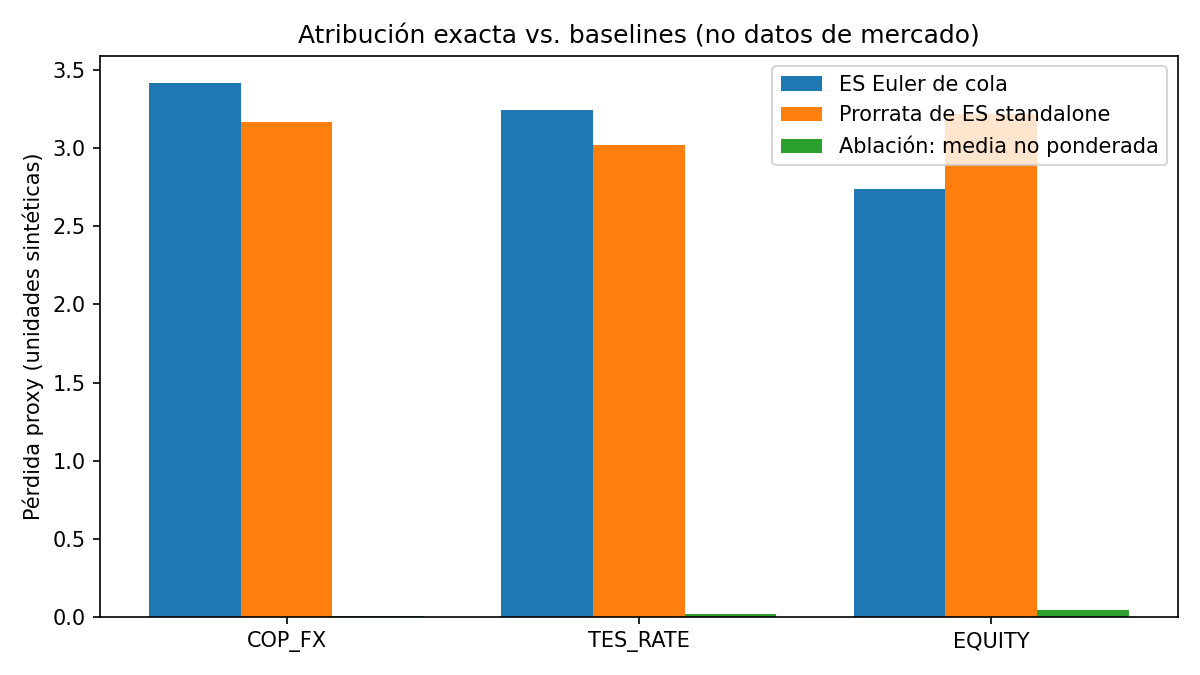

In [2]:
figure_path = Path('results/attribution.png')
assert figure_path.is_file()
print(f'Figura generada: {figure_path}')